# The Data Science Workflow in Engineering

Engineers have always worked with data: test bench measurements, calibration curves, quality records, field failures. What has changed is the *amount* and the *variety* of data. A modern production line logs hundreds of signals per second, a wind turbine reports its state every few seconds, and simulation studies produce thousands of runs. Data science provides the methods to turn such data into decisions.

This chapter sets the stage. We clarify what data are, what makes data science in engineering special and how it relates to statistics, machine learning and AI. We introduce a process model that structures every project and get to know the Python tools we will use throughout the course. Finally, we load and inspect our first dataset and use it to answer a business question.

::: {.scenario}
**Scenario: the day-ahead commitment**

You have just joined the trading desk of a combined cycle power plant. Every day at noon, the plant must commit its electrical output for each hour of the next day to the power exchange. Every megawatt-hour delivered more or less than committed is settled at an unfavourable price. Until now, the desk has simply committed the long-term average output for every hour. Your colleague suggests using tomorrow's temperature forecast instead – but the team lead is sceptical: "Is that really worth the effort?"

**Your decision:** Keep the flat commitment or switch to a temperature-based estimate?
:::

**Learning goals.** After this chapter you can

- define what we mean by data, determine the type and role of a variable and recognise tables that are not data,
- explain how we use the terms statistics, machine learning, deep learning, artificial intelligence and data science, and where they overlap,
- describe the phases of a data science project (CRISP-DM) and apply them to an engineering problem,
- distinguish the main data science tasks: description, inference, prediction and diagnosis,
- use the Python data stack (NumPy, pandas, Matplotlib, seaborn) in Jupyter or Google Colab,
- load a dataset from a public repository,
- produce a first overview of a dataset (size, types, summary statistics, pair plots) and interpret it,
- turn a model result into a business decision with a simple cost model.

**Datasets in this chapter**

- [Combined Cycle Power Plant (UCI)](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant) – original publication: P. Tüfekci, *Prediction of full load electrical power output of a base load operated combined cycle power plant using machine learning methods*, International Journal of Electrical Power & Energy Systems 60 (2014), 126–140, [doi:10.1016/j.ijepes.2014.02.027](https://doi.org/10.1016/j.ijepes.2014.02.027)

## What are data?

Before we talk about data *science*, we should be clear about what we mean by *data*. The word is used loosely – for a spreadsheet, a database, a folder of images, "the numbers". For this course we use a sharper definition.

::: {.callout-note}
## Definition: Data
**Data** are recorded values of **variables** (characteristics such as temperature, torque or fault type), **observed** on **observational units** (parts, machines, test runs, points in time) – together with the **context** needed to interpret them: what was measured, how, where, when and in which unit of measurement.
:::

The four highlighted terms deserve a closer look.

**Variables** are *what* is recorded – temperature, torque, fault type. Their type determines how they can be analysed (see below).

**Observational units** are *what the values belong to*: a part, a machine, a test run, a point in time. This is not always obvious – one shaft, or one of several measurements on that shaft? The answer decides what counts as an independent observation, which will matter when data are split into training and test sets (Chapter 10). In the power plant example of this chapter, the unit is one hour of plant operation.

**Observed, not specified.** Data record how things *actually turned out*: the diameter a coordinate measuring machine found on a particular shaft, the fact that pump no. 17 failed after 3,412 hours. This distinguishes data from specifications, targets and tables computed from a formula, which state how things *should* be (see below). Because data record outcomes, they can contradict our expectations – this is what makes them valuable.

**Context (metadata).** The value `293` means nothing without its context: a temperature in kelvin? A pressure in mbar? A part number? Unit, sensor, sampling rate, time zone and the definition of each variable belong to the data. They are usually documented separately as **metadata** – and often lost.

::: {.callout-warning}
## Pitfall: numbers without context
In 1999 NASA lost the *Mars Climate Orbiter* because one software component delivered thruster impulse data in pound-force seconds while the receiving component expected newton seconds. Every number was correct – the context was not. Before analysing a dataset, make sure you know the unit and the meaning of every column.
:::

### Data as a table

Most methods in this course expect data as a table whose layout follows directly from the definition. This layout is called *tidy data*:

- each **row** is one observation – one unit, or one unit at one point in time,
- each **column** is one variable,
- each **cell** holds one value.

Many real files are not tidy – a separate column for every day, two quantities in one cell – and must be reshaped first (in pandas with `melt` or `pivot`). Signals and images are data, too, even though they do not come as such a table (see below).

### Types of variables

The type of a variable determines which summaries, plots and models make sense (@fig-variable-types). A variable is either **categorical** – its values are labels such as "supplier B" – or **numeric** – its values are amounts such as 3.2 mm or 5 defects. Categorical variables are *nominal* (unordered) or *ordinal* (ordered); a nominal variable with only two categories, such as failure yes/no, is called **binary**. Numeric variables are *discrete* (countable) or *continuous* (any value in a range).

![Types of variables with engineering examples.](images/variable-types.png){#fig-variable-types width=75%}

For numeric variables we compute means, standard deviations and histograms; for categorical variables we count frequencies and draw bar charts. The type also decides which calculations are meaningful at all. Coding a category as a number does not make it numeric: the mean of the fault codes 1, 2 and 7 is meaningless. And even for numeric variables, not every calculation makes sense: 20 °C is 10 K warmer than 10 °C, but not "twice as warm", because the zero of the Celsius scale is arbitrary – in kelvin, ratios are meaningful.

In the power plant data, all five variables are continuous, which is typical for process data. Two kinds of data need special treatment:

- **Time stamps** are numeric – the difference between two time stamps is a duration – and mostly serve as the index of a time series.
- **Signals, images and texts** consist of many values per unit, e.g. thousands of samples of a vibration recording. They are condensed into a few informative variables, so-called *features* (next section) – either computed by hand, such as the RMS value of a signal (Chapter 10), or learned by a neural network (Chapter 12).

### Roles of variables: target and features

Besides its type, a variable has a role in an analysis. In the power plant example, we want to predict the electrical output from the ambient conditions and the condenser pressure:

- The **target** is the variable we want to explain or predict – here the net electrical output (`PE`). It is also called *output*; in classification (Chapter 7), the target is usually called *label*.
- The **features** are the variables used to explain or predict it – here ambient temperature, ambient pressure, relative humidity and condenser pressure (`AT`, `AP`, `RH`, `V`). They are also called *inputs*.

Features can be measured directly or derived from other variables – the hour of the day from a time stamp, the RMS value from a vibration signal. Constructing such features is called **feature engineering**; it is where engineering knowledge enters a model most directly (Chapters 10 and 11).

The role depends on the question, not on the variable: the ambient temperature is a feature when we predict the power output, but the target when we forecast the weather. And not every analysis has a target – in unsupervised learning (Chapter 9), we look for structure among the features alone.

### Something that looks like data – but is not

Consider a table with one row per dimension of a turned shaft – diameter at bearing seat, length, roundness – and columns *nominal value*, *upper tolerance*, *lower tolerance*. It has rows, columns, numbers and units. Is it data?

In the sense of our definition: **no**. The table comes from the technical drawing and describes how the shaft *should* be – a **specification**. It contains no observation of any real shaft. Fitting a model to it would tell us something about the designer's choices, not about the manufacturing process. The **data** are the values the coordinate measuring machine records on the shafts actually produced. Only by comparing them with the specification can we learn something about the process – for example its capability.

Similar cases: a table computed from a formula (a steam table) contains no information beyond the formula; a production plan is not a record of production.

::: {.callout-tip}
## Simulated data
Data generated by a simulation are observations of a **model**, not of reality. They are extremely useful – for training, for testing methods, when real failures are rare – but every conclusion holds for the simulated system only, and transfers to reality only as far as the simulation is valid. Two datasets in this course are simulated: the AI4I predictive maintenance data and the C-MAPSS turbofan data. We will keep this in mind when interpreting results.
:::

## What is data science in engineering?

Put briefly, data science is the systematic extraction of knowledge and decisions from data. It combines *statistics* (how to reason under uncertainty), *computer science* (how to process data and fit models efficiently) and *domain knowledge* (what the data mean and which questions matter). How this relates to statistics, machine learning and AI is sorted out in the next section.

The third ingredient is where engineers have a decisive advantage. A data scientist without engineering background may find that the vibration level of a pump correlates with the time of day; an engineer knows that this is because the pump runs at higher load during the day shift – and asks the right follow-up question.

Typical tasks fall into four groups:

| Task | Question | Engineering example | Chapters |
| --- | --- | --- | --- |
| **Description** | What happened? | Distribution of tensile strength in a batch | 2, 3 |
| **Inference** | Is the effect real? | Did the new supplier change the scrap rate? | 4, 5 |
| **Prediction** | What will happen? | Remaining useful life of a bearing, tomorrow's grid load | 5–8, 11, 12 |
| **Diagnosis / detection** | What is wrong? | Which fault type? Is this run abnormal? | 7–10 |

Engineering data have some characteristic properties that we will meet again and again:

- **Physics behind the data.** Relationships are often known in principle (energy balance, material laws). Good models use this knowledge instead of ignoring it.
- **Rare events.** Failures and defects are – fortunately – rare. This makes them hard to learn from (Chapter 7).
- **Time and sequence.** Sensor data are time series. Neighbouring values are not independent, which has consequences for validation (Chapter 11).
- **Measurement chains.** Every value went through sensor, amplifier, A/D converter, logging system. Each step can introduce errors, offsets, gaps and wrong units (Chapter 2).
- **High cost of errors.** A wrong prediction can mean an unplanned standstill or a safety issue. Uncertainty must be quantified and communicated.

## Statistics, machine learning, deep learning, AI: sorting the terms

You have certainly heard all of these terms – and probably noticed that they are used inconsistently. Product brochures call a linear regression "AI", job advertisements use "data science" and "machine learning" interchangeably, and research communities draw the borders differently. There is no official definition. For this course we therefore fix **working definitions**: not the only possible ones, but clear enough to know what we are talking about.

::: {.callout-note}
## Working definitions used in this course
- **Statistics** is the science of learning from data under uncertainty: collecting data (sampling, design of experiments), describing them, and drawing conclusions with a quantified uncertainty (estimates, confidence intervals, tests). Its focus is on *understanding* the process that generated the data.
- **Machine learning (ML)** is the field of algorithms that learn a task from examples instead of being explicitly programmed. Its focus is on *predicting* well on new, unseen data; models are judged by their performance on held-out test data.
- **Deep learning (DL)** is the part of machine learning that uses neural networks with many layers. Such networks learn suitable features by themselves, directly from the raw values – the pixels of an image, the samples of a signal, the words of a text – but typically need large amounts of data and computing power.
- **Artificial intelligence (AI)** is the broadest term: systems that perform tasks which would require intelligence if done by humans – perceiving, reasoning, planning, deciding. Machine learning is today the dominant approach to AI, but not the only one: rule-based expert systems or search and planning algorithms are AI without learning.
- **Data science** is the whole process of turning data into knowledge and decisions – from the question via data acquisition, preparation, analysis and modelling to communication and deployment. It *uses* statistics and machine learning as tools and requires domain knowledge to ask the right questions and interpret the answers.
:::

![Working definitions used in this course. (a) Competences: data science lives where statistics, computer science and domain knowledge meet; any two of them alone fall short. (b) Methods: deep learning is part of machine learning, which is part of AI; statistics overlaps strongly with machine learning ("statistical learning") but also covers methods outside of it, which are not AI.](images/ds-terms.png){#fig-terms width=100%}

The two panels answer different questions. Panel (a) asks what you need to *know*: data science combines three **competences**, and leaving out any one of them leads to typical problems – models that answer the wrong engineering question, analyses that do not scale to large data, or powerful tools used without an understanding of uncertainty. Panel (b) asks what kind of *method* you use and arranges the **method families**.

This is why statistics appears in both panels, with different meanings. In (a), it is a competence that every data analysis needs – machine learning included. In (b), it is a family of methods, of which only one part, statistical learning, also belongs to machine learning and thus to AI; a hypothesis test or a confidence interval is statistics, but not AI. Data science itself does not appear in (b) as a separate region, because it is defined by its process and purpose, not by a particular class of methods.

### Extension: And what about AI?

"Artificial intelligence" is the oldest and the broadest of the terms – and today the most overloaded one. The field was founded in the 1950s with the goal of making machines perform tasks that require intelligence. For decades, the dominant approach was **symbolic AI**: knowledge was written down by experts as rules ("if bearing temperature > 90 °C and vibration rising, then …") and combined by logical inference. Such *expert systems* worked in narrow domains but were laborious to build and brittle when reality deviated from the rules.

The alternative is to **learn** the behaviour from data – machine learning. Since around 2012, deep neural networks have achieved breakthroughs in image recognition, speech and text, and today's *generative AI* (large language models such as the chatbots you know, image generators) is deep learning trained on enormous amounts of data. This is why "AI" in everyday language now usually means deep learning – but the term formally covers much more.

Two distinctions help to keep a clear head:

- **Narrow vs. general AI.** All AI systems in practical use, including large language models, are built for specific kinds of tasks. A system that matches humans across all intellectual tasks (*artificial general intelligence*) does not exist and remains a matter of research and debate.
- **Legal vs. technical meaning.** The EU AI Act defines "AI system" broadly – roughly, a machine-based system that infers from its input how to produce outputs such as predictions, recommendations or decisions – and attaches obligations depending on the risk of the application. For engineers this means that even a fairly simple machine learning model in a safety-relevant product can fall under regulation.

In this course we rarely use the word AI. We say precisely which method we use – a test, a regression, a random forest, a neural network – because that determines its assumptions, its limits and how it must be validated.

### Where statistics and machine learning differ – and where they overlap

The boundary between statistics and machine learning is the most blurred one, because both fit models to data and many methods belong to both. The difference lies mainly in the **goal** and the **culture** – the statistician Leo Breiman famously spoke of "two cultures":

| | Statistics | Machine learning |
| --- | --- | --- |
| Main goal | understand and explain: which factors matter, how strong, how certain? | predict accurately on new data |
| Typical question | "Does the coolant temperature significantly affect the tool wear?" | "Which tool will fail within the next 100 parts?" |
| Models | few parameters, interpretable, explicit assumptions | flexible, often many parameters, "black box" accepted |
| Data | often small, carefully designed experiments | often large, observational ("whatever was logged") |
| Validation | model assumptions, standard errors, tests | performance on held-out test data, cross-validation |
| Typical output | estimate ± uncertainty, p-value | prediction, score, class |

The overlap is large: linear and logistic regression, principal component analysis and Gaussian processes are standard tools in both communities – this common ground is often called **statistical learning**. In this course we use both perspectives: when we fit a regression model in Chapter 5, we look at coefficients and confidence intervals (statistics) *and* at the prediction error on test data (machine learning).

::: {.callout-important}
## How this course is positioned
- Chapters 3–5 are mainly **statistics**: distributions, uncertainty, tests, regression, design of experiments.
- Chapters 6–11 are **statistical learning and machine learning**: model selection, classification, ensembles, unsupervised learning, signals and time series.
- Chapter 12 gives a first look at **deep learning**.
- AI methods without learning are not covered. All chapters together follow the **data science** process described next.
:::

::: {.callout-warning}
## Pitfall: buzzwords instead of methods
When a supplier advertises an "AI-based" monitoring system, ask what is behind it: a threshold rule, a regression model, a random forest or a neural network? How was it validated, on which data, with which error rates? The label says nothing about the quality – the validation does.
:::

## The CRISP-DM process model

Data science projects fail more often for organisational reasons than for mathematical ones: the wrong question was answered, the data did not contain the necessary information, or the model was never used. Process models help to avoid this. The most widely used is CRISP-DM.

::: {.callout-note}
## Definition: CRISP-DM
The *Cross-Industry Standard Process for Data Mining* (CRISP-DM) divides a data science project into six phases: business understanding, data understanding, data preparation, modelling, evaluation and deployment. The phases are passed through iteratively, not strictly one after another.
:::

![The CRISP-DM process model. The phases form a cycle around the data; in practice, the project moves back and forth between them.](images/crisp-dm.png){#fig-crisp width=65%}

What the phases mean in engineering – in general and for the day-ahead commitment of our scenario:

1. **Engineering understanding** (*business understanding* in the original model). Which decision should the analysis support, and what does a wrong answer cost? *Power plant:* which output to commit for each hour of the next day. Every MWh of deviation costs money, so the criterion is economic: switch if the annual savings exceed the annual cost of the temperature-based procedure. At noon, only a temperature *forecast* for tomorrow is available.
2. **Data understanding.** Which data exist, how were they measured, and are the relevant influences measured at all? *Power plant:* 9,568 hourly averages at full load – hours below 420 MW were removed during cleaning, so a model is only valid for this operating state. There are no time stamps, and the temperatures are measured values, not forecasts.
3. **Data preparation.** Cleaning, merging data sources, resampling, handling missing values, constructing features – in practice usually the largest part of a project. *Power plant:* little to do, the table is complete and tidy. In operation, plant records would have to be merged with weather forecasts; Chapter 2 shows the pitfalls of raw weather files.
4. **Modelling.** Choosing and fitting models – always together with a simple baseline. *Power plant:* the baseline is the flat long-term average, the model a straight line for the output as a function of the ambient temperature.
5. **Evaluation.** Does the model answer the question, under all relevant conditions, and is it better than the baseline? *Power plant:* translate the deviations of both rules into annual costs and compare them (*Back to the decision*).
6. **Deployment.** Integration into a process, a control system or a report – including monitoring whether the model stays valid. *Power plant:* every day before noon, compute the commitment from the forecast and record the actual deviations.

::: {.callout-tip}
## Engineering practice: start with a baseline
Before fitting any sophisticated model, compute a trivial baseline: the mean value, yesterday's value, or a simple physical formula. Every model must beat the baseline – otherwise its complexity is not justified. Surprisingly often, it does not.
:::

::: {.callout-warning}
## Pitfall: answering the wrong question
A model that predicts *when* a machine fails is useless if maintenance can only be scheduled four weeks in advance and the model warns two days ahead. Clarify the decision and its time horizon in phase 1 – it determines which data and models make sense.
:::

## Tools: the Python data stack

Python has become the standard language for data science because of its readable syntax and a large ecosystem of open-source libraries. We use the following packages:

| Package | Purpose | Typical objects / functions |
| --- | --- | --- |
| NumPy | n-dimensional arrays, linear algebra, random numbers | `np.array`, `np.mean`, `np.linalg` |
| pandas | tables and time series, reading and writing files | `DataFrame`, `Series`, `read_csv`, `groupby`, `resample` |
| Matplotlib | plotting (low level, full control) | `plt.plot`, `plt.subplots` |
| seaborn | statistical plots (high level) | `sns.histplot`, `sns.pairplot`, `sns.boxplot` |
| SciPy | statistics, signal processing, optimisation | `scipy.stats`, `scipy.signal`, `scipy.optimize` |
| statsmodels | statistical models with classical output tables | `smf.ols` |
| scikit-learn | machine learning with a uniform interface | `fit`, `predict`, `Pipeline` |
| PyTorch | neural networks (Chapter 12) | `torch.nn` |

The central data structure is the pandas **DataFrame**: a table whose columns have names and data types and whose rows have an index – for time series typically a time stamp. Most operations are *vectorised*: instead of looping over rows, we apply an operation to a whole column at once, which is shorter and much faster.

::: {.callout-tip}
## Working with notebooks
The demo notebooks of the lectures run in [Google Colab](https://colab.research.google.com) as well as in a local installation (see the Preface). Packages that are not preinstalled can be installed from a notebook cell with `%pip install`. In Colab, files you download or upload live only as long as the session; save results you want to keep to Google Drive or download them.
:::

In [1]:
#| code-fold: false
# Setup – every chapter starts with a cell like this one.

# 1) Install packages that are not pre-installed in Google Colab or Anaconda.
#    The list depends on the chapter (here it is only one package). The loop
#    checks each package and installs it only if it is missing, so running the
#    cell a second time costs nothing.
import importlib.util, subprocess, sys
for pkg in ["ucimlrepo"]:
    if importlib.util.find_spec(pkg) is None:        # package not found?
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# 2) Import the standard data stack (pre-installed in Colab and Anaconda).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")                     # common style for all plots

## Live coding: a first look at the power plant data

A combined cycle power plant (CCPP) combines a gas turbine with a steam turbine (@fig-ccpp). The gas turbine draws in ambient air, compresses it, burns natural gas in it and drives a generator. Its exhaust gas is still hot enough to raise steam in a heat recovery steam generator; the steam drives a second turbine and generator. Behind the steam turbine, the steam is condensed again in a condenser cooled by water or air. The plant that supplied our dataset, located in Turkey, has a nominal capacity of 480 MW: two gas turbines of 160 MW each, two heat recovery steam generators and one steam turbine of 160 MW ([Tüfekci 2014](https://doi.org/10.1016/j.ijepes.2014.02.027)).

![Simplified block diagram of a combined cycle power plant with the variables of the dataset. The features (blue) describe the ambient air and the condenser; the target (orange) is the net electrical output of gas turbine and steam turbine together.](images/ccpp.png){#fig-ccpp width=100%}

Why does the weather matter? Warm weather reduces the output twice:

- **Gas turbine:** warm air is less dense. The compressor draws in a smaller mass of air per second, so less fuel can be burnt and the gas turbine delivers less power.
- **Steam turbine:** a turbine delivers the more power, the larger the pressure difference between its inlet and its outlet. Cold cooling water condenses the steam well and keeps the pressure in the condenser low. On warm days, the cooling water is warmer, the condenser pressure rises and the steam turbine delivers less power.

This is why the condenser pressure is closely linked to the ambient temperature – and why we expect the output to fall when either of them rises.

The dataset contains 9,568 hourly averages from 674 days in six years (2006–2011), all with the plant at full load. The variables are:

| Column | Meaning | Unit | Role |
| --- | --- | --- | --- |
| `AT` | ambient temperature | °C | feature |
| `V` | exhaust vacuum: pressure in the condenser behind the steam turbine | cm Hg (according to the documentation – see below) | feature |
| `AP` | ambient pressure | mbar | feature |
| `RH` | relative humidity | % | feature |
| `PE` | net electrical output (hourly average) | MW | target |

The package `ucimlrepo` downloads datasets from the UCI Machine Learning Repository directly into pandas.

In [2]:
#| code-fold: false
from ucimlrepo import fetch_ucirepo

# Download dataset no. 294 (Combined Cycle Power Plant) from the UCI repository.
# The number is part of the address of the dataset page:
# archive.ics.uci.edu/dataset/294/combined+cycle+power+plant
ccpp = fetch_ucirepo(id=294)

# ucimlrepo returns the features (AT, V, AP, RH) and the target (PE) as two
# separate tables (see "Roles of variables"). pd.concat puts them side by side
# into one DataFrame; axis=1 means "join as columns", not as rows.
df = pd.concat([ccpp.data.features, ccpp.data.targets], axis=1)

df.info()   # number of rows, column names, data types, non-missing values

<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB


`df.info()` tells us the number of rows, the column names, the data types and the number of non-missing values per column. Check the data types first: pandas stores a column as numbers (`float64`, `int64`) only if *every* entry can be read as a number. A single entry such as `12,5` (decimal comma) or `n/a` (a text marker for a missing value) turns the whole column into text, shown as `object`. Calculations then fail or give nonsense – sorted as text, `"10"` comes before `"9"`. The fix is usually an argument of `read_csv`, e.g. `decimal=","` or `na_values=["n/a"]`. A numeric missing value code such as `-999` does not change the type; it shows up only in the summary statistics (see the weather data in Chapter 2).

Here, all five columns are numeric and complete. The repository also supplies metadata – part of the *context* in the sense of our definition:

In [3]:
#| code-fold: false
ccpp.variables   # metadata supplied by the repository: name, role, type, description, unit

,name,role,type,demographic,description,units,missing_values
0,AT,Feature,Continuous,None,in the range 1.81°C and 37.11°C,C,no
1,V,Feature,Continuous,None,in teh range 25.36-81.56 cm Hg,cm Hg,no
2,AP,Feature,Continuous,None,in the range 992.89-1033.30 milibar,milibar,no
3,RH,Feature,Continuous,None,in the range 25.56% to 100.16%,%,no
4,PE,Target,Continuous,None,420.26-495.76 MW,MW,no


Metadata are only as good as the care that went into them – the unit of `V` will show this in a moment.

Next, summary statistics:

In [4]:
#| code-fold: false
df.describe().round(2)   # one column per variable; round to 2 decimals for readability

,AT,V,AP,RH,PE
count,9568.00,9568.00,9568.00,9568.00,9568.00
mean,19.65,54.31,1013.26,73.31,454.37
std,7.45,12.71,5.94,14.60,17.07
min,1.81,25.36,992.89,25.56,420.26
25%,13.51,41.74,1009.10,63.33,439.75
50%,20.34,52.08,1012.94,74.97,451.55
75%,25.72,66.54,1017.26,84.83,468.43
max,37.11,81.56,1033.30,100.16,495.76


::: {.callout-tip}
## How to read `describe()`
Look at each column with an engineer's eye: Are minimum and maximum physically plausible? Is the mean close to the median (50 %)? A large difference indicates a skewed distribution or outliers. Is the standard deviation large or small compared with the measurement accuracy you would expect?
:::

For the power plant, most ranges are plausible: ambient temperatures from just above freezing to the mid-thirties, ambient pressures around 1013 mbar, and an output of roughly 420 to 500 MW. The relative humidity reaches slightly more than 100 % – physically impossible, but within the accuracy of a humidity sensor near saturation. Worth noticing, not worth correcting.

The lower limit of the output is no coincidence: according to the original publication, all hours below 420.26 MW were removed as "out of range" during data cleaning. The dataset therefore contains only hours of high output – a model fitted to it says nothing about weaker operating states.

The exhaust vacuum `V` does not fit, though. According to the documentation – and already the original publication – it is given in cm Hg, but a vacuum of up to 81.6 cm Hg is impossible: the atmosphere itself corresponds to only about 76 cm Hg. Moreover, `V` behaves like a pressure, not like a vacuum: the larger `V`, the lower the output (see the pair plot below). The values would fit the absolute pressure in the condenser if the unit were mm Hg – a single wrong letter – or mbar. The data alone cannot settle this. For predicting `PE`, the unit does not matter; for any physical interpretation, it does. This is exactly what *numbers without context* means.

A pair plot shows all pairwise relationships at once:

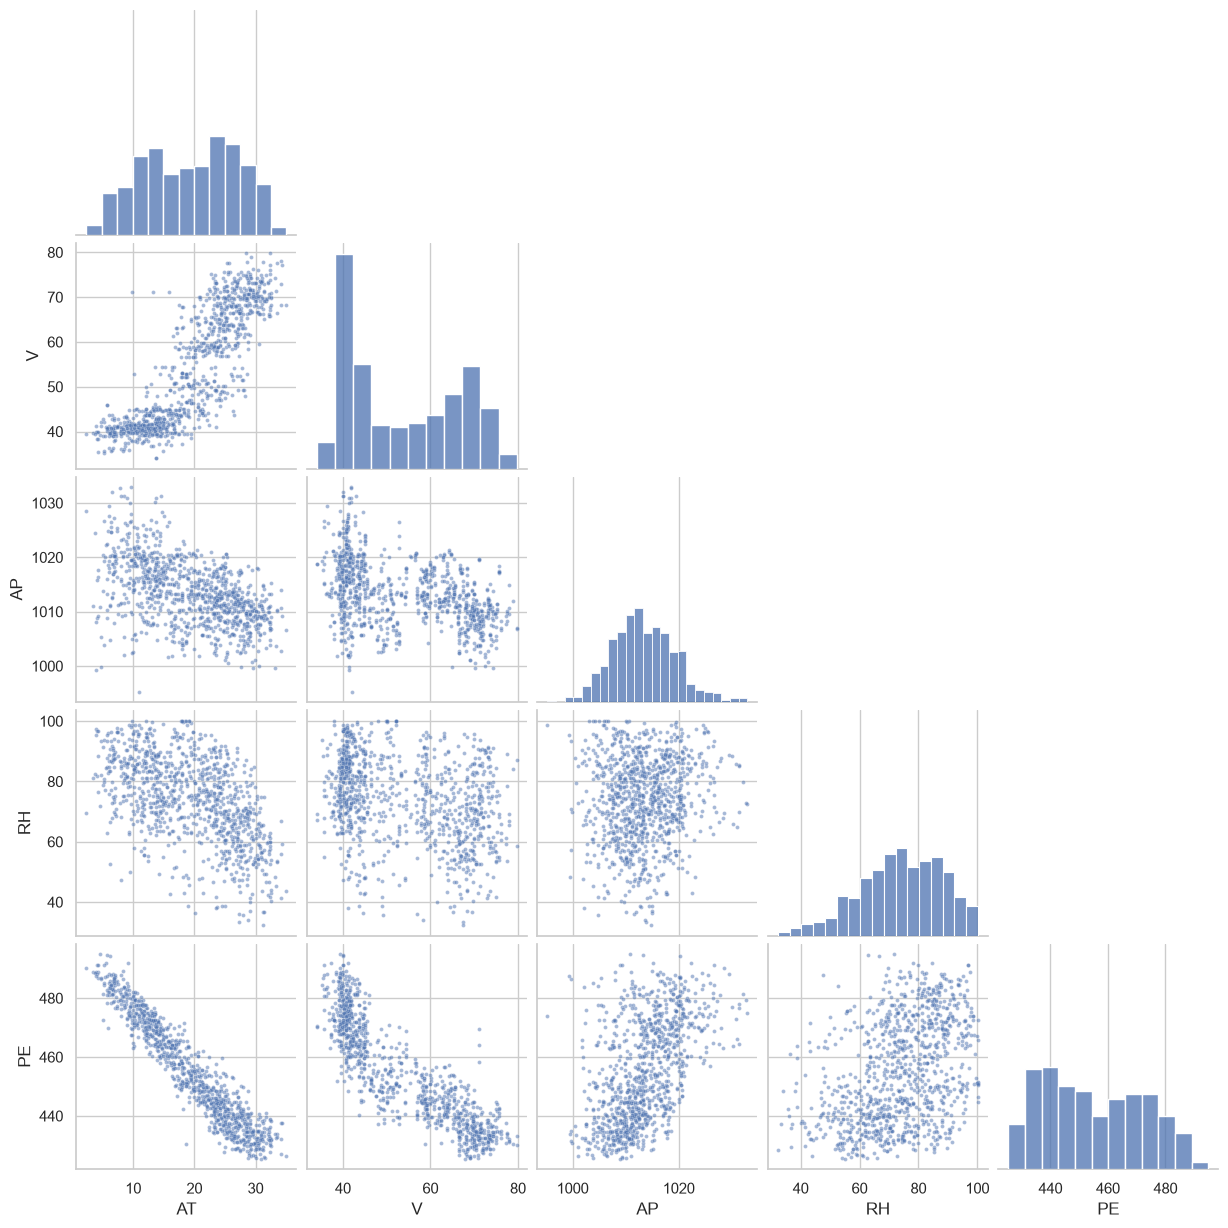

In [5]:
# Pair plot: a scatter plot for every pair of variables, a histogram of each
# variable on the diagonal.
sns.pairplot(
    df.sample(1000, random_state=0),   # random subset of 1,000 of the 9,568 rows
                                       # (avoids overplotting); random_state=0 draws
                                       # the same rows every time the cell is run
    corner=True,                       # lower triangle only – the upper one would
                                       # show the same plots mirrored
    plot_kws={"s": 8, "alpha": 0.5},   # small (s = marker size), semi-transparent
                                       # points (alpha = 0.5), so dense regions
                                       # appear darker
)
plt.show()

**Discussion.** The pair plot is the most informative single figure for a small tabular dataset. Several observations stand out:

- `PE` decreases almost linearly with ambient temperature `AT` – this is the strongest relationship in the data and has a clear physical explanation (air density and mass flow).
- `PE` also decreases with the condenser pressure `V`, as expected from the plant (@fig-ccpp).
- `AT` and `V` are strongly correlated with each other – warm weather means warmer cooling. Such correlated features (*collinearity*) make it hard to separate their individual effects – we will return to this in Chapter 5.
- Ambient pressure and humidity show weaker, more diffuse relationships with the output.

We plotted a random sample of 1,000 points; with all 9,568 points the scatter plots would be overplotted. Sampling is a simple and legitimate trick for visual exploration – but never for computing the final statistics.

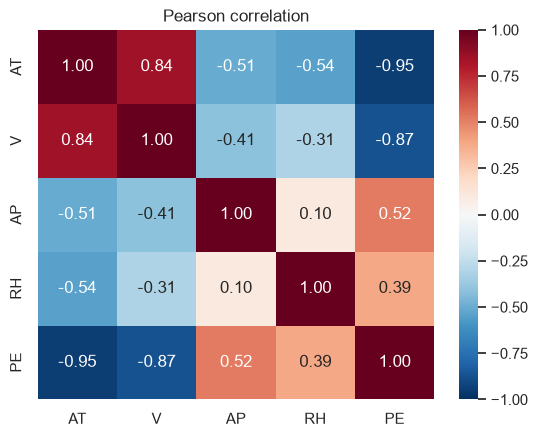

In [6]:
#| code-fold: false
corr = df.corr()                      # Pearson correlation of every pair of columns
sns.heatmap(
    corr,
    annot=True, fmt=".2f",            # write each value into its cell, with 2 decimals
    cmap="RdBu_r",                    # diverging colour map: red = positive,
                                      # blue = negative (_r: reversed order of "RdBu")
    vmin=-1, vmax=1,                  # colour scale over the full range of r, so that
                                      # white always means r = 0
)
plt.title("Pearson correlation")
plt.show()

::: {.callout-note}
## Definition: Pearson correlation coefficient
For two variables $x$ and $y$ with $n$ observations,
$$r_{xy} = \frac{\sum_{i=1}^n (x_i - \bar x)(y_i - \bar y)}{\sqrt{\sum_{i=1}^n (x_i - \bar x)^2}\,\sqrt{\sum_{i=1}^n (y_i - \bar y)^2}} \in [-1, 1].$$
It measures the strength of a **linear** relationship: $r = \pm 1$ means all points lie on a straight line, $r = 0$ means no linear relationship.
:::

::: {.callout-warning}
## Pitfall: correlation is not causation – and not every relationship is linear
A correlation near zero does not mean "no relationship": $y = x^2$ on a symmetric interval has $r = 0$. And a strong correlation does not prove a causal effect: both variables may be driven by a third one. In the power plant, `V` correlates with `PE` partly *because* both depend on the ambient temperature.
:::

### A first simple model

To make the engineering question concrete, we fit the simplest possible model: a straight line for `PE` as a function of `AT`. We will treat regression properly in Chapter 5; here we only compare the line with the trivial baseline that always predicts the mean.

In [7]:
#| code-fold: false
slope, intercept = np.polyfit(df["AT"], df["PE"], deg=1)   # least-squares straight line
                                                             # (polynomial of degree 1)
pred = intercept + slope * df["AT"]                          # predicted output for every hour
rmse = np.sqrt(np.mean((df["PE"] - pred) ** 2))              # root mean squared error
print(f"PE ≈ {intercept:.1f} MW {slope:+.2f} MW/°C · AT,   RMSE = {rmse:.1f} MW")
# The RMSE of the constant prediction "mean" is (almost exactly) the standard deviation.
print(f"Baseline 'always predict the mean': RMSE = {df['PE'].std():.1f} MW")

PE ≈ 497.0 MW -2.17 MW/°C · AT,   RMSE = 5.4 MW
Baseline 'always predict the mean': RMSE = 17.1 MW


The line explains most of the variation: its error (root mean squared error, RMSE) is a fraction of the error of the trivial mean-value baseline. Each additional degree Celsius costs about two megawatts of output. Whether an error of a few MW is "good enough" is not a statistical question – it depends on the use case defined in CRISP-DM phase 1.

## Back to the decision

In terms of CRISP-DM, this is phase 5, evaluation: we check the result against the criterion fixed in phase 1. The trading desk compares two rules for the committed output: the flat long-term average and the straight-line estimate from the ambient temperature. To turn the comparison into an economic decision, we use a deliberately simple cost model. All figures are assumptions for illustration:

- **Deviation cost:** every MWh delivered more or less than committed costs 30 € extra. (Real imbalance prices vary strongly from hour to hour and can be much higher.)
- **Operating hours:** the plant runs at full load all 8,760 hours of a year – the data contain full-load hours only.
- **Cost of the new rule:** a weather forecast service, implementation and maintenance cost 25,000 € per year.

The average deviation in MW – the **mean absolute error** (MAE) – times the number of hours gives the deviation in MWh per year, and times the price its cost. We switch if the annual savings exceed the annual cost of the new rule.

In [8]:
#| code-fold: false
# Simple cost model – all figures are assumptions for illustration
price_dev = 30          # € per MWh of deviation (extra cost compared with an exact commitment)
hours = 8760            # full-load hours per year (simplification: the plant always runs)
cost_rule = 25_000      # € per year for the temperature-based rule: forecast service,
                        # implementation and maintenance

flat_commitment = df["PE"].mean()                                     # rule 1: long-term average
mae_flat = (df["PE"] - flat_commitment).abs().mean()                 # mean absolute error (MW)
mae_temp = (df["PE"] - (intercept + slope * df["AT"])).abs().mean()  # rule 2: straight line

# MW of deviation x hours = MWh of deviation per year; x price = cost per year
cost_flat = mae_flat * hours * price_dev
cost_temp = mae_temp * hours * price_dev
savings = cost_flat - cost_temp

print(f"Average deviation:  flat {mae_flat:5.1f} MW         temperature-based {mae_temp:5.1f} MW")
print(f"Deviation cost:     flat {cost_flat / 1e6:5.2f} M€ per year  temperature-based {cost_temp / 1e6:5.2f} M€ per year")
print(f"Savings: {savings / 1e6:.2f} M€ per year,  cost of the new rule: {cost_rule / 1e6:.3f} M€ per year")
if savings > cost_rule:                                               # criterion from phase 1
    print(f"Decision: switch to the temperature-based estimate "
          f"(net benefit {(savings - cost_rule) / 1e6:.2f} M€ per year).")
else:
    print("Decision: keep the flat commitment – the savings do not cover the costs.")

# How robust is the decision? Suppose the deviation of rule 2 doubled in operation.
savings_2x = (mae_flat - 2 * mae_temp) * hours * price_dev
print(f"Robustness: with twice the deviation, the savings would still be {savings_2x / 1e6:.2f} M€ per year.")

Average deviation:  flat  14.8 MW         temperature-based   4.3 MW
Deviation cost:     flat  3.90 M€ per year  temperature-based  1.13 M€ per year
Savings: 2.77 M€ per year,  cost of the new rule: 0.025 M€ per year
Decision: switch to the temperature-based estimate (net benefit 2.75 M€ per year).
Robustness: with twice the deviation, the savings would still be 1.65 M€ per year.


Two caveats belong in the recommendation to the team lead. First, we evaluated the rule on the same data we used to fit it; Chapter 6 shows how to evaluate on unseen data. Second, in operation the rule receives a temperature *forecast*, whose error adds to the error of the model. Both points make the real benefit smaller. The last line of the output shows how much room there is: even if the deviation of the temperature-based rule doubled in operation, the savings would still exceed the cost of the rule many times over. And the approach is not a textbook fiction: the plant that supplied the data uses such a model for its next-day commitment, with the temperature forecast of the national weather service as input, and reports a mean relative error below 2 % in operation ([Tüfekci 2014](https://doi.org/10.1016/j.ijepes.2014.02.027)).

The cost model is a simplification, too – Exercise 6 asks you to question it. Its value lies elsewhere: it turns "the error is smaller" into "the switch is worth this much per year", which is the language in which the team lead has to decide.

::: {.callout-important}
## Key takeaways
- Data are recorded values of variables, observed on observational units, together with their context. Without unit and meaning, numbers cannot be interpreted – as the condenser pressure `V` shows.
- Type and role of a variable determine which summaries and models make sense.
- Every data science project starts with a precise engineering question and a clear criterion for success (CRISP-DM phase 1) – ideally expressed in money, as in the cost model of the power plant.
- Look at the data before modelling: `info()`, `describe()`, pair plots and correlations reveal structure and problems quickly.
- Always compare a model with a simple baseline.
:::

## Exercises

<div class="exercises">

1. Which columns of the power plant data are features, which is the target? Which physical relationships between them do you expect, and which signs of the correlations follow from them?
2. Fit straight lines for `PE` against each of the four features separately and compare their RMSE. Which single feature is the best predictor? Does the ranking agree with the correlation matrix?
3. Sketch the six CRISP-DM phases for a project from your own engineering background. Which phase do you expect to be the most difficult?
4. Place the following in @fig-terms (b) and justify: (a) a t-test whether a new supplier changes the scrap rate; (b) a convolutional neural network that detects cracks in X-ray images; (c) route planning for automated guided vehicles with the A* search algorithm; (d) a random forest that predicts tool breakage; (e) a straight line for power output vs. temperature with a confidence interval for the slope.
5. Which of the following are data in the sense of our definition? (a) The torque values logged by a screwdriving station for every screw joint; (b) the maximum torque in the screwdriver's datasheet; (c) a table of thread friction coefficients computed with a formula from a handbook; (d) 10,000 lifetimes generated by a reliability simulation; (e) a column `T` with values between 280 and 320, without any further information.
6. Use the cost model from *Back to the decision*. (a) At which deviation price would the savings just cover the cost of the new rule (break-even)? (b) How large may the average deviation of the temperature-based rule become in operation before switching no longer pays off? (c) Which simplifications of the cost model would you question first, and in which direction would they change the result?

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1
The features are the ambient conditions `AT`, `AP`, `RH` and the condenser pressure `V`; the target is `PE`. Strictly speaking, `V` is not an ambient condition but a plant variable – it depends on the cooling water temperature and therefore also on the weather (@fig-ccpp).

Expected signs: higher ambient temperature lowers air density and thus the mass flow and power of the gas turbine → negative correlation of `AT` with `PE`. A higher condenser pressure (worse vacuum, larger `V` in this dataset) reduces the pressure difference across the steam turbine → negative correlation of `V` with `PE`. Higher ambient pressure increases air density → positive correlation. Humidity has a smaller, less obvious effect. The correlation matrix confirms these signs.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2

In [9]:
#| code-fold: false
rows = []
for col in ["AT", "V", "AP", "RH"]:                       # one straight line per feature
    b1, b0 = np.polyfit(df[col], df["PE"], deg=1)         # slope b1, intercept b0
    rmse_col = np.sqrt(np.mean((df["PE"] - (b0 + b1 * df[col])) ** 2))
    rows.append({"feature": col, "slope": b1, "RMSE (MW)": rmse_col, "r": df[col].corr(df["PE"])})
pd.DataFrame(rows).sort_values("RMSE (MW)").round(3)      # best feature first

,feature,slope,RMSE (MW),r
0,AT,-2.171,5.425,-0.948
1,V,-1.168,8.421,-0.870
2,AP,1.490,14.594,0.518
3,RH,0.456,15.716,0.390


`AT` gives by far the smallest RMSE, followed by `V`. For a straight-line fit, the ranking by RMSE is exactly the ranking by $|r|$, because the fraction of explained variance of a simple linear regression is $r^2$. The original publication reports practically the same values ([Tüfekci 2014](https://doi.org/10.1016/j.ijepes.2014.02.027)).
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3
There is no single correct answer. A good sketch states a concrete decision in phase 1 (e.g. "decide weekly which tools to replace"), names the data sources and their owners in phase 2, lists expected preparation steps in phase 3 (merging, time alignment), names a baseline in phase 4, an evaluation criterion tied to the decision in phase 5 (e.g. cost of unplanned stops), and a realistic deployment path in phase 6. Many practitioners name phase 2/3 (data access and quality) or phase 6 (deployment and acceptance) as the hardest.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4
\(a) **Statistics** – inference about a difference with quantified uncertainty, no prediction task.

\(b) **Deep learning** (and thus ML and AI) – a neural network learns features from raw images.

\(c) **AI without machine learning** – A* is a search algorithm; nothing is learned from data.

\(d) **Machine learning** – a flexible model optimised for predictive accuracy; it is not deep learning.

\(e) The **overlap of statistics and machine learning**: the same linear model, used here in the statistical way (interpretation of the slope and its uncertainty). Used purely to predict output for the day-ahead market and validated on test data, it would be viewed as machine learning.

The examples show that the method alone does not determine the category – the purpose matters too.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5
\(a) **Data** – recorded observations of real screw joints (provided we know the unit and which joint each value belongs to).

\(b) **Not data** – a specification of what the tool is designed for, not an observation.

\(c) **Not data** about any real joint – the table only re-expresses the formula; a model fitted to it would rediscover the formula.

\(d) **Data about a model** – valid observations of the simulation; conclusions hold for real products only as far as the simulation is valid.

\(e) **Not usable as data** – the numbers might be temperatures in kelvin, but without unit, sensor and time stamp they cannot be interpreted. They become data once the context is recovered.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 6

In [10]:
#| code-fold: false
# (a) price at which the savings equal the cost of the rule
price_break = cost_rule / ((mae_flat - mae_temp) * hours)
# (b) deviation of rule 2 at which the savings equal the cost of the rule
mae_break = mae_flat - cost_rule / (hours * price_dev)
print(f"(a) break-even price:     {price_break:.2f} € per MWh (assumed: {price_dev} € per MWh)")
print(f"(b) break-even deviation: {mae_break:.1f} MW (today: {mae_temp:.1f} MW, flat rule: {mae_flat:.1f} MW)")

(a) break-even price:     0.27 € per MWh (assumed: 30 € per MWh)
(b) break-even deviation: 14.7 MW (today: 4.3 MW, flat rule: 14.8 MW)


\(a) Even a deviation price far below 1 € per MWh would cover the cost of the rule – real prices are much higher.

\(b) The rule pays off as long as it is even slightly better than the flat commitment: the break-even deviation lies only about 0.1 MW below that of the flat rule. With well over 100,000 MWh of deviation per year, even small improvements are worth a lot of money.

\(c) For example: deviations in the two directions are usually priced differently, and the price depends on the state of the grid; the plant does not run at full load in every hour (maintenance, partial load), so fewer hours mean smaller savings; the forecast error of the temperature increases the deviation of the new rule; and the cost of the new rule may be underestimated (staff time, IT). None of these is likely to reverse the decision here – but in a project with a smaller margin, each of them could.
:::